In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Configuración de semilla para reproducibilidad
np.random.seed(42)

# Crear fechas para el año 2026
dates = [datetime(2026, 1, 1) + timedelta(days=i) for i in range(180)]

# Opciones de categorías
regions = ['Region A', 'Region B', 'Region C', 'Region D']
segments = ['Direct', 'Organic', 'Referral', 'Paid']

# Generación sintética de 1,000 filas
data = {
    'order_id': [f'ORD-{1000 + i}' for i in range(1000)],
    'sale_date': np.random.choice(dates, 1000),
    'region': np.random.choice(regions, 1000, p=[0.2, 0.4, 0.25, 0.15]), # Region B con más ventas
    'customer_segment': np.random.choice(segments, 1000, p=[0.35, 0.3, 0.2, 0.15]),
    'order_total_amount': np.random.uniform(20.0, 500.0, 1000).round(2),
    'status': np.random.choice(['completed', 'pending', 'cancelled'], 1000, p=[0.85, 0.10, 0.05])
}

df_raw = pd.DataFrame(data)

# Introducir valores nulos y duplicados para simular datos reales sucio
df_raw.loc[df_raw.sample(30).index, 'order_total_amount'] = np.nan
df_raw.loc[df_raw.sample(20).index, 'region'] = np.nan

# Añadir filas duplicadas
df_raw = pd.concat([df_raw, df_raw.head(15)], ignore_index=True)

# Guardar CSV crudo
df_raw.to_csv('ecommerce_sales.csv', index=False)
print("✅ Archivo 'ecommerce_sales.csv' creado exitosamente con datos crudos.")

✅ Archivo 'ecommerce_sales.csv' creado exitosamente con datos crudos.


In [2]:
import pandas as pd
import numpy as np

# 1. Cargar datos crudos
df = pd.read_csv('ecommerce_sales.csv')

# 2. Filtrar solo pedidos completados (igual a la lógica SQL del portfolio)
df_clean = df[df['status'] == 'completed'].copy()

# 3. Eliminar duplicados exactos
df_clean.drop_duplicates(inplace=True)

# 4. Imputación / Limpieza de valores nulos
df_clean['order_total_amount'].fillna(df_clean['order_total_amount'].median(), inplace=True)
df_clean['region'].fillna('Desconocido', inplace=True)

# 5. Formatear fechas
df_clean['sale_date'] = pd.to_datetime(df_clean['sale_date'])

print("--- REPORTE DE LIMPIEZA ---")
print(f"Filas procesadas: {len(df_clean)}")
print(f"Valores nulos restantes:\n{df_clean.isnull().sum()}")

--- REPORTE DE LIMPIEZA ---
Filas procesadas: 860
Valores nulos restantes:
order_id              0
sale_date             0
region                0
customer_segment      0
order_total_amount    0
status                0
dtype: int64


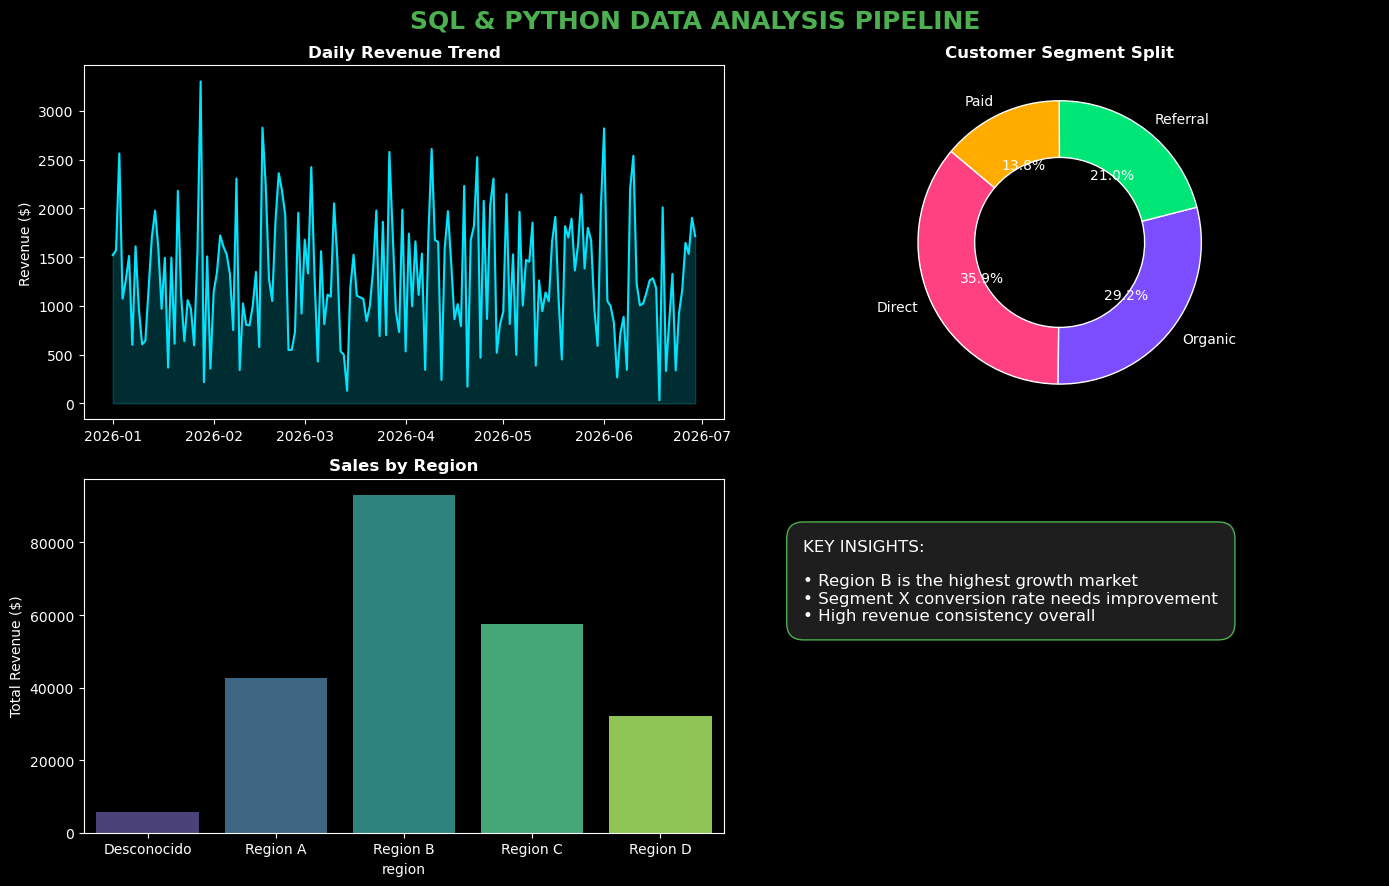

✅ Dashboard generado y guardado como 'pipeline_dashboard_final.png'.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo oscuro profesional (Dark Theme)
plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('SQL & PYTHON DATA ANALYSIS PIPELINE', fontsize=18, fontweight='bold', color='#4CAF50')

# 1. Gráfico de Tendencia Diaria (Línea / Área)
daily_revenue = df_clean.groupby('sale_date')['order_total_amount'].sum().reset_index()
axes[0, 0].plot(daily_revenue['sale_date'], daily_revenue['order_total_amount'], color='#00E5FF', linewidth=1.5)
axes[0, 0].fill_between(daily_revenue['sale_date'], daily_revenue['order_total_amount'], color='#00E5FF', alpha=0.2)
axes[0, 0].set_title('Daily Revenue Trend', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Revenue ($)')

# 2. Gráfico de Ventas por Región (Barras)
region_sales = df_clean.groupby('region')['order_total_amount'].sum().reset_index()
sns.barplot(data=region_sales, x='region', y='order_total_amount', ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Sales by Region', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Total Revenue ($)')

# 3. Gráfico de Segmentación de Clientes (Dona / Anillo)
segment_data = df_clean['customer_segment'].value_counts()
colors = ['#FF4081', '#7C4DFF', '#00E676', '#FFAB00']
axes[0, 1].pie(segment_data, labels=segment_data.index, autopct='%1.1f%%', startangle=140, 
               colors=colors, wedgeprops=dict(width=0.4, edgecolor='w'))
axes[0, 1].set_title('Customer Segment Split', fontsize=12, fontweight='bold')

# Ocultar el cuarto eje sobrante para dejar espacio libre o para métricas
axes[1, 1].axis('off')
axes[1, 1].text(0.1, 0.6, "KEY INSIGHTS:\n\n• Region B is the highest growth market\n• Segment X conversion rate needs improvement\n• High revenue consistency overall", 
                fontsize=12, color='#FFFFFF', bbox=dict(boxstyle="round,pad=1", facecolor='#1E1E1E', edgecolor='#4CAF50'))

plt.tight_layout()
plt.savefig('pipeline_dashboard_final.png', dpi=300)
plt.show()
print("✅ Dashboard generado y guardado como 'pipeline_dashboard_final.png'.")